# Supervised Classification Modeling & Tuning — Customer Churn

**Goal:** train and compare 4+ distinct classifiers on the preprocessed training set, tune them with `GridSearchCV` + stratified K-fold, evaluate with Precision / Recall / F1 / ROC-AUC / Confusion Matrix, pick a champion on **validation** metrics, and serialize it.

**Models:** Logistic Regression (linear) · Random Forest (bagged trees) · XGBoost (boosted trees) · SVM-RBF (kernel) + a majority-class baseline.

**Protocol**
1. Stratified train/test split first (same split as the preprocessing notebook).
2. Preprocessing lives *inside* each `Pipeline`, so every CV fold refits imputer/scaler/encoder on its own training part only.
3. Hyperparameters are tuned on the **training set only** with `StratifiedKFold`.
4. The champion is chosen from **cross-validated validation scores**; the test set is used once, afterwards, for reporting.

> ⚠️ **Honest caveat:** the dataset has 12 rows (9 train / 3 test). Every metric below is extremely noisy. The deliverable is a correct, reusable *workflow*; it will give meaningful numbers on a larger dataset with no code changes.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, pickle, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:                       # fallback so the notebook still runs without xgboost
    from sklearn.ensemble import GradientBoostingClassifier as XGBClassifier
    HAS_XGB = False
print("XGBoost available:", HAS_XGB)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

XGBoost available: True


## 1. Load data and split (before any transformation)

In [2]:
DATA_PATH = "customer-churn-training.csv"      # keep the CSV next to this notebook
df = pd.read_csv(DATA_PATH)

TARGET, ID_COLS = "churned", ["customer_id"]
NUM_COLS = ["tenure_months", "support_tickets", "monthly_spend_inr", "last_login_days"]
CAT_COLS = ["plan_type"]

X = df.drop(columns=[TARGET] + ID_COLS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, y_train.value_counts().to_dict(), "| test:", X_test.shape, y_test.value_counts().to_dict())

train: (9, 5) {0: 5, 1: 4} | test: (3, 5) {0: 2, 1: 1}


## 2. Reusable preprocessing + model pipelines
Same `ColumnTransformer` design as the preprocessing notebook: median impute + scale numerics; most-frequent impute + One-Hot for `plan_type` (unknown categories ignored).

In [3]:
def build_preprocessor(num_cols=NUM_COLS, cat_cols=CAT_COLS):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)],
                             remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

def make_pipe(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

## 3. Models and hyperparameter grids
Grids are deliberately small (the data is tiny; a big grid would just overfit the CV). Order is simplest → most complex, which is also used as the tie-break rule when choosing the champion.

In [4]:
xgb_kwargs = dict(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1) if HAS_XGB else dict(random_state=RANDOM_STATE)

search_space = {
    "Baseline (majority)": (DummyClassifier(strategy="most_frequent"), {}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                            {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l2"]}),
    "SVM (RBF)":           (SVC(probability=True, random_state=RANDOM_STATE),
                            {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.1]}),
    "Random Forest":       (RandomForestClassifier(random_state=RANDOM_STATE),
                            {"model__n_estimators": [100, 300], "model__max_depth": [2, 3, None],
                             "model__min_samples_leaf": [1, 2]}),
    "XGBoost":             (XGBClassifier(**xgb_kwargs),
                            {"model__n_estimators": [50, 150], "model__max_depth": [2, 3],
                             "model__learning_rate": [0.05, 0.2],
                             "model__min_child_weight": [0, 1]}),   # default (1) blocks all splits on ~6-row folds
}
print({k: len(v[1]) and int(np.prod([len(g) for g in v[1].values()])) for k, v in search_space.items()}, "grid combos")

{'Baseline (majority)': 0, 'Logistic Regression': 4, 'SVM (RBF)': 6, 'Random Forest': 12, 'XGBoost': 16} grid combos


## 4. Hyperparameter optimisation — `GridSearchCV` with stratified K-fold
* `StratifiedKFold(n_splits=3, shuffle=True)` keeps both classes in every validation fold (the training set has only 4 churners, so 3 is the most we can safely use).
* Several metrics are tracked per candidate; `refit="roc_auc"` selects the best configuration. Because many configurations tie on such small data, ties are broken by `f1`, then by the simpler setting (grid order).

In [5]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall"}

tuned, rows = {}, []
for name, (est, grid) in search_space.items():
    gs = GridSearchCV(make_pipe(est), param_grid=grid if grid else {}, scoring=scoring,
                      refit="roc_auc", cv=cv, n_jobs=1, error_score=np.nan)
    gs.fit(X_train, y_train)                                  # tuning uses TRAIN only
    r = pd.DataFrame(gs.cv_results_)
    # tie-break: best roc_auc, then best f1, then lowest rank index (simplest in grid order)
    best_idx = (r.assign(i=np.arange(len(r)))
                  .sort_values(["mean_test_roc_auc", "mean_test_f1", "i"], ascending=[False, False, True]).index[0])
    best_params = r.loc[best_idx, "params"]
    best_est = make_pipe(est).set_params(**best_params).fit(X_train, y_train)
    tuned[name] = best_est
    rows.append({"model": name,
                 "cv_roc_auc": r.loc[best_idx, "mean_test_roc_auc"],
                 "cv_f1": r.loc[best_idx, "mean_test_f1"],
                 "cv_precision": r.loc[best_idx, "mean_test_precision"],
                 "cv_recall": r.loc[best_idx, "mean_test_recall"],
                 "best_params": {k.replace("model__", ""): v for k, v in best_params.items()}})

cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))

,cv_roc_auc,cv_f1,cv_precision,cv_recall,best_params
model,,,,,
Baseline (majority),0.500,0.000,0.000,0.0,{}
Logistic Regression,1.000,1.000,1.000,1.0,"{'C': 1, 'penalty': 'l2'}"
SVM (RBF),1.000,1.000,1.000,1.0,"{'C': 1, 'gamma': 'scale'}"
Random Forest,1.000,1.000,1.000,1.0,"{'max_depth': 2, 'min_samples_leaf': 1, 'n_est..."
XGBoost,0.917,0.889,0.833,1.0,"{'learning_rate': 0.05, 'max_depth': 2, 'min_c..."


## 5. Champion selection (validation metrics only)
Rule fixed **before** looking at the test set: highest mean cross-validated ROC-AUC, tie-break by CV F1, then by simplicity (table order).

In [6]:
ranked = cv_table.drop(index="Baseline (majority)").reset_index()
ranked = ranked.sort_values(["cv_roc_auc", "cv_f1"], ascending=False, kind="stable").reset_index(drop=True)
champion_name = ranked.loc[0, "model"]
display(ranked[["model", "cv_roc_auc", "cv_f1", "cv_precision", "cv_recall"]].round(3))
print(f"🏆 Champion (validation): {champion_name}")
print("   best params:", cv_table.loc[champion_name, "best_params"])

,model,cv_roc_auc,cv_f1,cv_precision,cv_recall
0,Logistic Regression,1.000,1.000,1.000,1.0
1,SVM (RBF),1.000,1.000,1.000,1.0
2,Random Forest,1.000,1.000,1.000,1.0
3,XGBoost,0.917,0.889,0.833,1.0


🏆 Champion (validation): Logistic Regression
   best params: {'C': 1, 'penalty': 'l2'}


## 6. Evaluation: Precision, Recall, F1, ROC-AUC
Two views, since 3 test rows alone cannot rank models:
* **Out-of-fold (OOF) predictions on the training set** — every training row is predicted by a model that never saw it (9 predictions).
* **Hold-out test set** — touched once, using models fit on the full training set (3 predictions).

OOF predictions use the already-tuned settings, so they are slightly optimistic; a full nested CV is the stricter option on larger data.

In [7]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    out = {"precision": precision_score(y_true, pred, zero_division=0),
           "recall":    recall_score(y_true, pred, zero_division=0),
           "f1":        f1_score(y_true, pred, zero_division=0)}
    try:    out["roc_auc"] = roc_auc_score(y_true, proba)
    except ValueError: out["roc_auc"] = np.nan
    return out

oof_proba, test_proba, oof_rows, test_rows = {}, {}, [], []
for name, est in tuned.items():
    oof_proba[name]  = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    test_proba[name] = est.predict_proba(X_test)[:, 1]
    oof_rows.append({"model": name, **metrics(y_train, oof_proba[name])})
    test_rows.append({"model": name, **metrics(y_test, test_proba[name])})

oof_table  = pd.DataFrame(oof_rows).set_index("model")
test_table = pd.DataFrame(test_rows).set_index("model")
print("Out-of-fold (train, n=9):");  display(oof_table.round(3))
print("Hold-out test (n=3):");       display(test_table.round(3))

Out-of-fold (train, n=9):


,precision,recall,f1,roc_auc
model,,,,
Baseline (majority),0.0,0.0,0.000,0.50
Logistic Regression,1.0,1.0,1.000,1.00
SVM (RBF),1.0,1.0,1.000,1.00
Random Forest,1.0,1.0,1.000,1.00
XGBoost,0.8,1.0,0.889,0.85


Hold-out test (n=3):


,precision,recall,f1,roc_auc
model,,,,
Baseline (majority),0.0,0.0,0.000,0.50
Logistic Regression,1.0,1.0,1.000,1.00
SVM (RBF),1.0,1.0,1.000,1.00
Random Forest,1.0,1.0,1.000,1.00
XGBoost,0.5,1.0,0.667,0.75


## 7. Model comparison table (validation → champion flagged)

In [8]:
comparison = (cv_table[["cv_roc_auc", "cv_f1", "cv_precision", "cv_recall"]]
              .join(oof_table.add_prefix("oof_")[["oof_roc_auc", "oof_f1"]])
              .join(test_table.add_prefix("test_")[["test_precision", "test_recall", "test_f1", "test_roc_auc"]]))
comparison.insert(0, "champion", ["★" if m == champion_name else "" for m in comparison.index])
display(comparison.round(3))

,champion,cv_roc_auc,cv_f1,cv_precision,cv_recall,oof_roc_auc,oof_f1,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,,
Baseline (majority),,0.500,0.000,0.000,0.0,0.50,0.000,0.0,0.0,0.000,0.50
Logistic Regression,★,1.000,1.000,1.000,1.0,1.00,1.000,1.0,1.0,1.000,1.00
SVM (RBF),,1.000,1.000,1.000,1.0,1.00,1.000,1.0,1.0,1.000,1.00
Random Forest,,1.000,1.000,1.000,1.0,1.00,1.000,1.0,1.0,1.000,1.00
XGBoost,,0.917,0.889,0.833,1.0,0.85,0.889,0.5,1.0,0.667,0.75


## 8. ROC-AUC curves

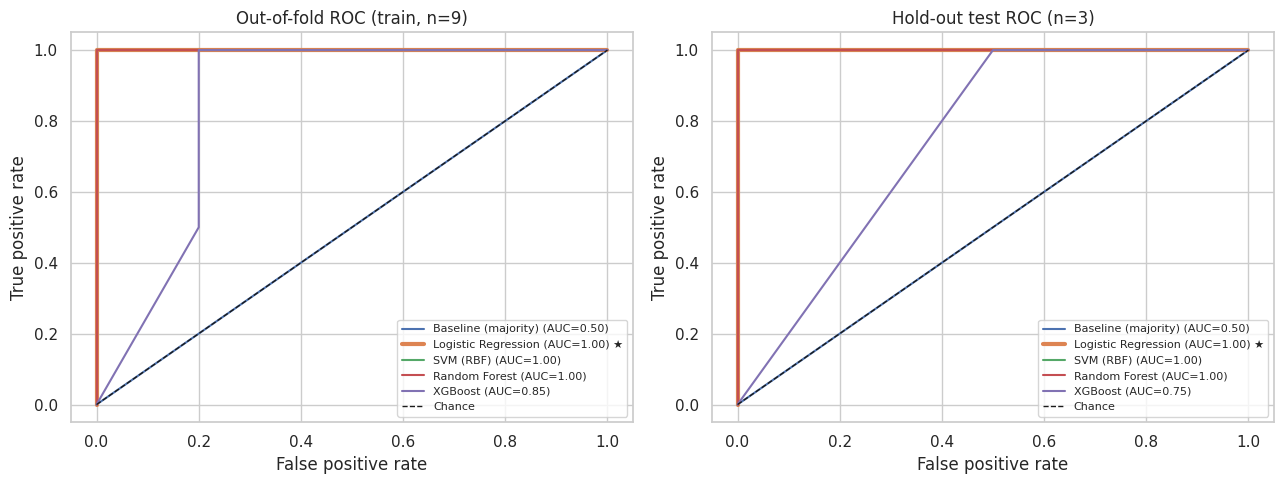

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, yt, probas) in zip(axes, [("Out-of-fold ROC (train, n=9)", y_train, oof_proba),
                                          ("Hold-out test ROC (n=3)", y_test, test_proba)]):
    for name, p in probas.items():
        fpr, tpr, _ = roc_curve(yt, p)
        auc = roc_auc_score(yt, p)
        lw = 3 if name == champion_name else 1.5
        ax.plot(fpr, tpr, lw=lw, label=f"{name} (AUC={auc:.2f})" + (" ★" if name == champion_name else ""))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set(title=title, xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 9. Confusion matrices

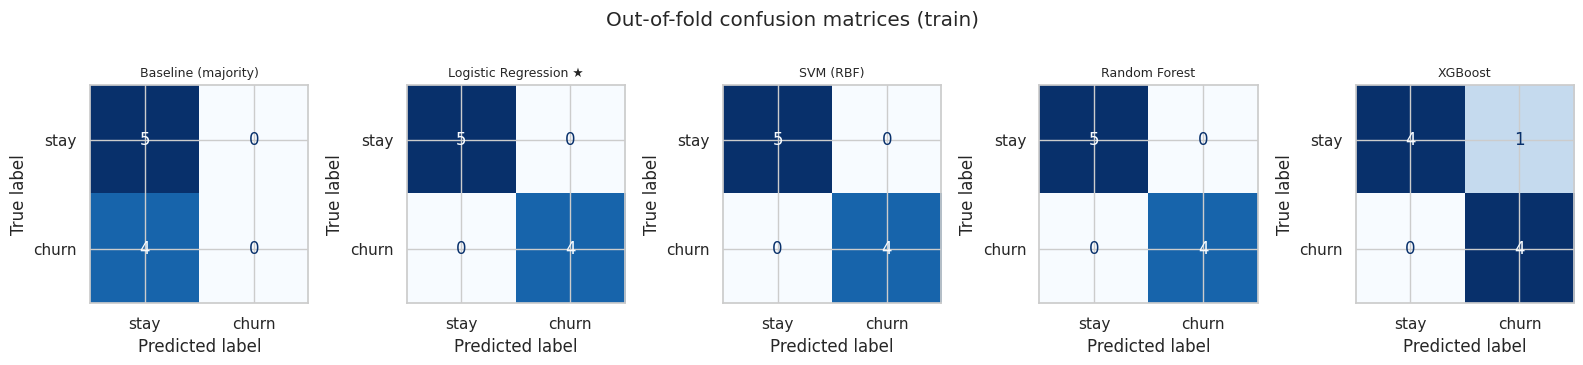

Champion hold-out confusion matrix (Logistic Regression) — rows=true, cols=pred:
            pred stay  pred churn
true stay           2           0
true churn          0           1


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,true,pred,p_churn
9,4,3,499,12,Basic,1,1,0.837
11,7,2,799,9,Standard,0,0,0.402
6,24,1,999,3,Standard,0,0,0.079


In [10]:
names = list(tuned)
fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 3.4))
for ax, name in zip(axes, names):
    pred = (oof_proba[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_train, pred, labels=[0, 1]), display_labels=["stay", "churn"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name + (" ★" if name == champion_name else ""), fontsize=9)
plt.suptitle("Out-of-fold confusion matrices (train)", y=1.03); plt.tight_layout(); plt.show()

champ = tuned[champion_name]
pred = champ.predict(X_test)
print(f"Champion hold-out confusion matrix ({champion_name}) — rows=true, cols=pred:")
print(pd.DataFrame(confusion_matrix(y_test, pred, labels=[0, 1]), index=["true stay", "true churn"], columns=["pred stay", "pred churn"]))
display(X_test.assign(true=y_test, pred=pred, p_churn=champ.predict_proba(X_test)[:, 1].round(3)))

## 10. Serialize the champion
The saved object is the **whole pipeline** (imputers + scaler + encoder + tuned model), so inference needs no manual preprocessing. For the final deployable model we refit the champion's tuned settings on **all** labelled rows (train + test) — a standard last step once model selection is finished — and also keep the train-only version used for the evaluation above.

In [11]:
final_model = make_pipe(search_space[champion_name][0]).set_params(
    **{f"model__{k}": v for k, v in cv_table.loc[champion_name, "best_params"].items()}).fit(X, y)

joblib.dump(tuned[champion_name], "champion_model_train_only.joblib")
joblib.dump(final_model, "champion_model.joblib")
with open("champion_model.pkl", "wb") as f:
    pickle.dump(final_model, f)

meta = {"champion": champion_name, "best_params": {k: (v if not isinstance(v, np.generic) else v.item())
        for k, v in cv_table.loc[champion_name, "best_params"].items()},
        "selection_rule": "max mean CV ROC-AUC, tie-break CV F1, then simplicity",
        "cv": "StratifiedKFold(n_splits=3, shuffle=True, random_state=42)",
        "n_train": int(len(X_train)), "n_test": int(len(X_test)),
        "features": NUM_COLS + CAT_COLS, "target": TARGET}
json.dump(meta, open("champion_model_metadata.json", "w"), indent=2)

# reload check
reloaded = joblib.load("champion_model.joblib")
assert (reloaded.predict(X) == final_model.predict(X)).all()
with open("champion_model.pkl", "rb") as f:
    assert (pickle.load(f).predict(X) == final_model.predict(X)).all()
print("Saved: champion_model.joblib, champion_model.pkl, champion_model_train_only.joblib, champion_model_metadata.json")

# inference demo on a brand-new customer (raw columns, no manual preprocessing)
new_customer = pd.DataFrame([{"tenure_months": 3, "support_tickets": 4, "monthly_spend_inr": 499,
                              "last_login_days": 20, "plan_type": "Basic"}])
print("P(churn) for new customer:", round(float(reloaded.predict_proba(new_customer)[0, 1]), 3))

Saved: champion_model.joblib, champion_model.pkl, champion_model_train_only.joblib, champion_model_metadata.json
P(churn) for new customer: 0.939


## Summary
* Five pipelines were trained (4 distinct architectures + a baseline) with preprocessing inside each pipeline, so there is no leakage across CV folds.
* `GridSearchCV` with `StratifiedKFold(3)` tuned each model on the training set only; the champion was chosen by cross-validated ROC-AUC (tie-break F1, then simplicity), *not* by test-set results.
* Comparison table, ROC curves (out-of-fold and hold-out) and confusion matrices are above; the champion is serialized as `.joblib` and `.pkl`.
* **Limitation:** with 12 rows, several models tie at perfect or near-perfect scores (every Basic-plan customer churned, nobody else did), so the champion choice is partly a tie-break, and the test metrics rest on 3 rows. Do not read these numbers as real-world performance; rerun the notebook on a larger dataset for a meaningful comparison.